# 03 — Phase 1 Risk Engines (Gaussian and Student-t)

**Tail Risk Adequacy — Stress-Testing Risk Metrics Across Distributional Assumptions and Market Regimes**
High_Magus_of_Risk

---

## Purpose

This notebook produces the **Phase 1 forecast dataset**: daily 1-day-ahead VaR and ES for each combination of (portfolio × engine), saved to disk for notebook 04 to backtest formally.

### Locked configuration (from notebook 02 design choices)

| Parameter | Value |
|---|---|
| Horizon | 1 day |
| Calibration | Rolling window, $W = 1{,}000$ trading days (~4 years) |
| Confidence | $\alpha = 99\%$ |
| Engines | Gaussian, Student-t at $\nu \in \{4, 6, 10\}$ — four engines total |
| Portfolios | `Port_FO` |
| Output | One CSV per portfolio in `data/forecasts/` with `VaR` and `ES` for each engine |

### Method (one paragraph)

For each forecast date $d$, slice the trailing $W$ portfolio returns ending the day before $d$, estimate $\hat{\sigma}_{d-1}$ by the sample standard deviation (with a zero conditional mean, the standard convention for 1-day VaR), plug into the closed-form VaR/ES expression of the chosen distribution, and store the resulting $(\mathrm{VaR}_d, \mathrm{ES}_d)$ at the index $d$. The realized loss on day $d$ is $L_d = -r_d$; an *exception* is any day where $L_d > \mathrm{VaR}_d$. The four engines differ only in the distributional shape — the rolling variance estimate is identical across engines, which makes the comparison cleanly attributable to **distributional assumption**.

The closed-form formulas live in `src/risk.py` and are unit-tested in `tests/test_risk.py` (run `python tests/test_risk.py` to verify before relying on results).

---
## 1  Environment Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make src/ importable
sys.path.insert(0, os.path.abspath('src'))
from risk import gaussian_var_es, student_t_var_es, rolling_var_es, backtest_var_es

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

---
## 2  Configuration

A single, named block of parameters. Every result downstream is keyed off these values; changing any of them only requires re-running this notebook (and notebook 04, which reads the saved forecasts).

In [2]:
CONFIG = {
    'window'    : 1000,                       # rolling estimation window (~3y)
    'alpha'     : 0.99,                        # confidence level
    'portfolios': ['Port_FO'],
    'engines'   : [                            # (name, engine, kwargs)
        ('Gaussian', 'gaussian', {}),
        ('t_nu10',   't',        {'nu': 10}),
        ('t_nu6',    't',        {'nu': 6}),
        ('t_nu4',    't',        {'nu': 4}),
    ],
    'portfolio_labels': {
        'Port_FO': 'Family-Office Portfolio (40/25/15/10/10)',
    },
    'engine_colors': {
        'Gaussian': '#1f77b4',
        't_nu10'  : '#f4a261',
        't_nu6'   : '#e76f51',
        't_nu4'   : '#9d0208',
    },
}
print(json.dumps({k: v for k, v in CONFIG.items() if k != 'engines'}, indent=2, default=str))
print('Engines:')
for name, eng, kw in CONFIG['engines']:
    print(f'  {name:10s} -> engine={eng:8s} kwargs={kw}')

{
  "window": 1000,
  "alpha": 0.99,
  "portfolios": [
    "Port_FO"
  ],
  "portfolio_labels": {
    "Port_FO": "Family-Office Portfolio (40/25/15/10/10)"
  },
  "engine_colors": {
    "Gaussian": "#1f77b4",
    "t_nu10": "#f4a261",
    "t_nu6": "#e76f51",
    "t_nu4": "#9d0208"
  }
}
Engines:
  Gaussian   -> engine=gaussian kwargs={}
  t_nu10     -> engine=t        kwargs={'nu': 10}
  t_nu6      -> engine=t        kwargs={'nu': 6}
  t_nu4      -> engine=t        kwargs={'nu': 4}


---
## 3  Load Returns and Stress Windows

We read the artifacts produced by notebook 01 (`returns.csv`) and notebook 02 (`stress_windows.json`). The stress windows are loaded here for reference only — the formal stress-period backtest lives in notebook 04.

In [3]:
returns = pd.read_csv('data/returns.csv', index_col=0, parse_dates=True)
print(f'Returns: {returns.shape[0]:,} obs  |  {returns.index.min().date()} → {returns.index.max().date()}')

with open('data/stress_windows.json') as f:
    STRESS_WINDOWS = json.load(f)
print(f'Stress windows loaded: {list(STRESS_WINDOWS.keys())}')

Returns: 7,485 obs  |  1996-05-14 → 2026-04-01
Stress windows loaded: ['DotCom_2000_2003', 'GFC', 'COVID', 'Rate_Hikes_2022']


---
## 4  Run the Four Engines on the FO Portfolio

Each engine produces a `(VaR_t, ES_t)` time series indexed by the forecast date. With $W = 1{,}000$, the first forecast is for the date is roughly 2000 given a 1996 start. We collect everything into a single nested dictionary keyed by `(portfolio, engine_name)`.

In [4]:
forecasts = {}   # (portfolio, engine_name) -> DataFrame[VaR, ES]

for port in CONFIG['portfolios']:
    r = returns[port].dropna()
    for name, engine, kw in CONFIG['engines']:
        fc = rolling_var_es(r, window=CONFIG['window'],
                            engine=engine, alpha=CONFIG['alpha'], **kw)
        forecasts[(port, name)] = fc
        print(f'  {port:<20s} | {name:8s} | '
              f'forecasts: {len(fc):,} | '
              f'first date: {fc.index.min().date()} | '
              f'mean VaR: {fc["VaR"].mean()*100:.3f}%')

  Port_FO              | Gaussian | forecasts: 6,485 | first date: 2000-05-17 | mean VaR: 1.567%
  Port_FO              | t_nu10   | forecasts: 6,485 | first date: 2000-05-17 | mean VaR: 1.665%
  Port_FO              | t_nu6    | forecasts: 6,485 | first date: 2000-05-17 | mean VaR: 1.728%
  Port_FO              | t_nu4    | forecasts: 6,485 | first date: 2000-05-17 | mean VaR: 1.785%


---
## 5  Sanity-Check Backtest

A high-level pass to confirm the engines are sane before we hand them to notebook 04. We report, per (portfolio × engine):

- **Exception rate** — empirical vs the target $1 - \alpha = 1\%$.
- **Mean realized loss on exception days** — the magnitude of breaches in absolute terms.
- **Mean ES severity** — average of $L_t - \mathrm{ES}_t$ on exception days. A positive number means the ES forecast *understated* the realized tail loss on average.

Expected pattern: Gaussian over-rejects (exception rate > 1%) because empirical tails are heavier than normal; t-engines should be closer to 1%, with the heaviest-tail engine ($\nu = 4$) potentially over-correcting.

In [5]:
rows = []
for port in CONFIG['portfolios']:
    for name, *_ in CONFIG['engines']:
        fc = forecasts[(port, name)]
        r = returns[port]
        result = backtest_var_es(r, fc, alpha=CONFIG['alpha'])
        rows.append({
            'Portfolio'        : CONFIG['portfolio_labels'][port],
            'Engine'           : name,
            'N obs'            : result['n_obs'],
            'N exceptions'     : result['n_exceptions'],
            'Exception rate'   : result['exception_rate'],
            'Expected rate'    : result['expected_exception_rate'],
            'Mean loss | exc'  : result['mean_loss_given_exception'],
            'Mean (L - ES)|exc': result['mean_es_severity'],
        })

backtest_df = pd.DataFrame(rows)
backtest_df_display = backtest_df.copy()
for c in ['Exception rate', 'Expected rate', 'Mean loss | exc', 'Mean (L - ES)|exc']:
    backtest_df_display[c] = backtest_df_display[c].map(lambda x: f'{x*100:+.3f}%' if pd.notna(x) else 'NaN')
display(backtest_df_display.set_index(['Portfolio', 'Engine']))

N obs  N exceptions  \
Portfolio                                Engine                          
Family-Office Portfolio (40/25/15/10/10) Gaussian   6485           135   
                                         t_nu10     6485           119   
                                         t_nu6      6485           112   
                                         t_nu4      6485            96   

                                                  Exception rate  \
Portfolio                                Engine                    
Family-Office Portfolio (40/25/15/10/10) Gaussian        +2.082%   
                                         t_nu10          +1.835%   
                                         t_nu6           +1.727%   
                                         t_nu4           +1.480%   

                                                  Expected rate  \
Portfolio                                Engine                   
Family-Office Portfolio (40/25/15/10/10) Gaussian       +1.000%   
                                         t_nu10         +1.000%   
                                         t_nu6          +1.000%   
                                         t_nu4          +1.000%   

                                                  Mean loss | exc  \
Portfolio                                Engine                     
Family-Office Portfolio (40/25/15/10/10) Gaussian         +2.131%   
                                         t_nu10           +2.216%   
                                         t_nu6            +2.246%   
                                         t_nu4            +2.352%   

                                                  Mean (L - ES)|exc  
Portfolio                                Engine                      
Family-Office Portfolio (40/25/15/10/10) Gaussian           +0.523%  
                                         t_nu10             +0.409%  
                                         t_nu6              +0.286%  
                                         t_nu4              +0.170%

---
## 6  Realized Loss vs VaR Lines

Per portfolio: a single time-series chart showing realized losses (grey sticks) overlaid with the four engines' VaR forecasts (lines). This is the visual that conveys the **distributional-assumption** story most directly — when the lines diverge during stress regimes (2000-03, 2008, 2020), each engine's tolerance for tail loss is visible at a glance.

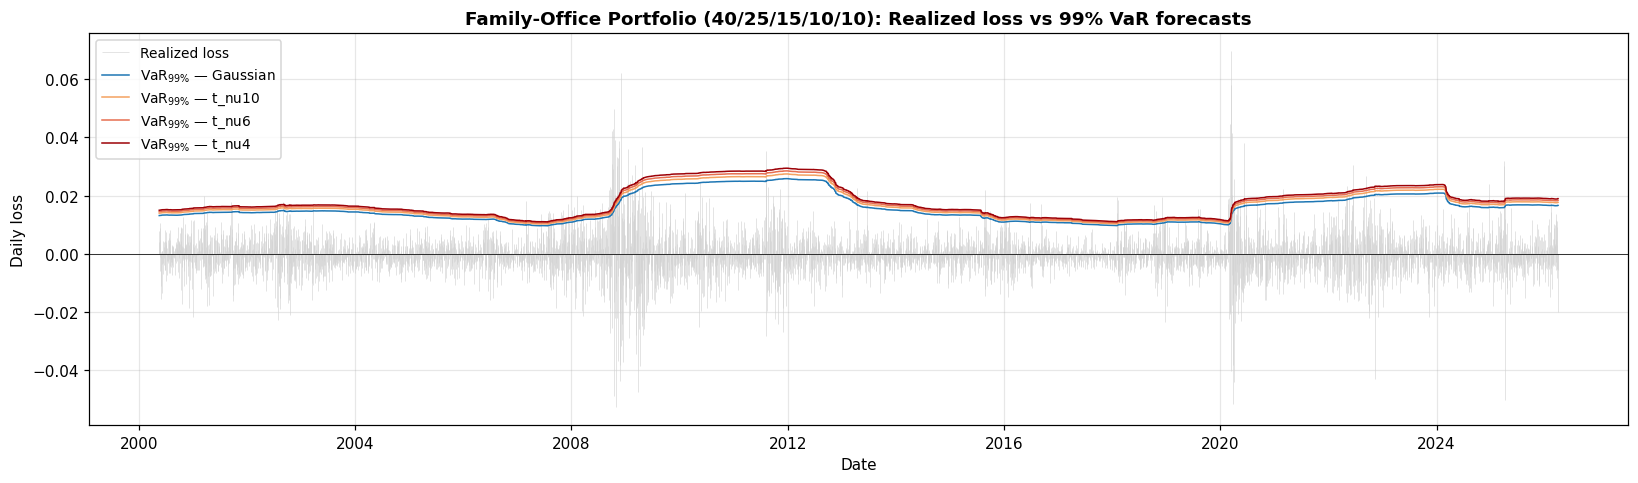

In [6]:
fig, axes = plt.subplots(len(CONFIG['portfolios']), 1,
                         figsize=(15, 4.5 * len(CONFIG['portfolios'])),
                         sharex=True)
axes = np.atleast_1d(axes)

for ax, port in zip(axes, CONFIG['portfolios']):
    # Realized loss
    losses = -returns[port]
    # Restrict the plot to the forecast period
    common_idx = forecasts[(port, 'Gaussian')].index
    L = losses.reindex(common_idx)
    ax.vlines(L.index, 0, L.values, color='lightgrey', lw=0.4, label='Realized loss')

    # VaR lines per engine
    for name, *_ in CONFIG['engines']:
        fc = forecasts[(port, name)]
        ax.plot(fc.index, fc['VaR'], lw=1.0,
                color=CONFIG['engine_colors'][name],
                label=f'VaR$_{{99\%}}$ — {name}')

    ax.set_title(f"{CONFIG['portfolio_labels'][port]}: Realized loss vs 99% VaR forecasts",
                 fontsize=12, fontweight='bold')
    ax.set_ylabel('Daily loss')
    ax.axhline(0, color='black', lw=0.5)
    ax.legend(loc='upper left', fontsize=9, ncol=1)

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

### Reading the plot

The most informative comparison is in the **stress periods** — the 2000-03 dot-com bear, 2008-09, March 2020, and 2022. In a calm regime, the four VaR lines hug each other closely (rolling $\hat{\sigma}_t$ is the dominant driver, and the distributional multiplier matters only modestly). When realized volatility spikes, the lines fan out: the Gaussian line stays *lowest* (least conservative), and the $\nu = 4$ line sits *highest* (most conservative). The sticks that pierce the Gaussian line but not the $\nu = 6$ or $\nu = 4$ line are exactly the exceptions that distinguish the engines empirically.

A small visible bias to flag: the rolling window adapts *gradually*. Right after a volatility spike (e.g., the day after a -6% return), the next-day VaR rises but only by approximately $1/W$ of the spike's contribution — visible as a step-up rather than a jump. This is the structural weakness of unfiltered rolling engines that motivates Phase 2 GARCH/FHS.

---
## 7  Save Forecasts to Disk

One CSV per portfolio in `data/forecasts/`. Each CSV has 8 numeric columns: `{engine}_VaR` and `{engine}_ES` for each of the 4 engines. Notebook 04 will read these directly.

In [7]:
os.makedirs('data/forecasts', exist_ok=True)

for port in CONFIG['portfolios']:
    pieces = []
    for name, *_ in CONFIG['engines']:
        fc = forecasts[(port, name)].copy()
        fc.columns = [f'{name}_VaR', f'{name}_ES']
        pieces.append(fc)
    out = pd.concat(pieces, axis=1)
    out_path = f'data/forecasts/{port}.csv'
    out.to_csv(out_path)
    print(f'  Saved → {out_path}  shape={out.shape}')

  Saved → data/forecasts/Port_FO.csv  shape=(6485, 8)


---
## 8  Summary & Next Steps

### Deliverables produced
- Four rolling 1-day-ahead engines × the FO portfolio = **four $(\mathrm{VaR}_t, \mathrm{ES}_t)$ forecast series**, each spanning approximately 1999 → March 2026 (~~6,800 forecast days).
- Sanity-check exception-rate table.
- Realized-loss-vs-VaR-lines time-series chart per portfolio.
- Forecasts persisted to `data/forecasts/Port_FO.csv` for downstream use.

### What the sanity check tells us at a glance
- Compare each engine's exception rate to the target $1 - \alpha = 1\%$.
- A Gaussian rate well above 1% is the classic fat-tails-rejected-by-the-data result and the central motivation for the t-engines.
- The "Mean (L - ES) | exception" column shows whether ES *systematically* understates realized tail losses — the diagnostic the design doc treats as the headline ES metric.

### Next notebook — `04_Backtest_and_Stress.ipynb`
1. Reload the eight forecast series from `data/forecasts/`.
2. Re-run the backtest function overall (already shown here) plus on each of the four stress windows defined in `data/stress_windows.json`.
3. Produce the **head-to-head comparison table** (rows = engine, columns = portfolio × metric).
4. Produce the **stress-window scorecard** (rows = window, columns = engine × metric).
5. Wrap up with the headline plot.

Anything beyond that — block bootstrap, FHS-GARCH filtering, MLE for $\nu$, drawdown layer, formal Kupiec/Christoffersen tests, 10-day horizon, weekly/monthly sensitivity — is reserved as Phase 2 robustness.